### Assignment 2 (4 scores):

- Use Numpy only to construct the Softmax Regression model.
- Train and evaluating (precision, recall, f1) the Softmax Regression model using the Gradient Descent approach **to classify 10 digit images** on the [MNIST](https://github.com/cvdfoundation/mnist?tab=readme-ov-file) dataset.
- Visualize the loss function of the training process.

In [19]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. Import thư viện
Import các thư viện cần thiết

In [20]:
import numpy as np
import matplotlib.pyplot as plt
import struct

## 2. Đọc dữ liệu MNIST
Xây dựng các hàm đọc ảnh và nhãn từ file IDX của bộ dữ liệu MNIST.

In [21]:
def load_images(filename):
    with open(filename, 'rb') as f:
        magic, num_images, rows, cols = struct.unpack(">IIII", f.read(16))
        images = np.frombuffer(f.read(), dtype=np.uint8)
        images = images.reshape(num_images, rows, cols)
    return images

def load_labels(filename):
    with open(filename, 'rb') as f:
        magic, num_labels = struct.unpack(">II", f.read(8))
        labels = np.frombuffer(f.read(), dtype=np.uint8)
    return labels

## 3. Load dữ liệu
Đọc toàn bộ tập train và test của MNIST gồm 10 chữ số từ 0 đến 9.

In [22]:
X_train = load_images("/content/drive/MyDrive/DS102/Lab2/data/train-images.idx3-ubyte")
y_train = load_labels("/content/drive/MyDrive/DS102/Lab2/data/train-labels.idx1-ubyte")

X_test = load_images("/content/drive/MyDrive/DS102/Lab2/data/t10k-images.idx3-ubyte")
y_test = load_labels("/content/drive/MyDrive/DS102/Lab2/data/t10k-labels.idx1-ubyte")

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_test :", X_test.shape)
print("y_test :", y_test.shape)

print("Train classes:", np.unique(y_train))
print("Test classes :", np.unique(y_test))

X_train: (60000, 28, 28)
y_train: (60000,)
X_test : (10000, 28, 28)
y_test : (10000,)
Train classes: [0 1 2 3 4 5 6 7 8 9]
Test classes : [0 1 2 3 4 5 6 7 8 9]


## 4. Tiền xử lý dữ liệu
Chuyển mỗi ảnh 28×28 thành vector 784 phần tử, chuẩn hóa giá trị pixel từ [0,255] về [0,1].

In [23]:
X_train = X_train.reshape(X_train.shape[0], -1)
X_test = X_test.reshape(X_test.shape[0], -1)

X_train = X_train.astype(np.float64) / 255.0
X_test = X_test.astype(np.float64) / 255.0

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)

print("Min:", X_train.min())
print("Max:", X_train.max())

X_train: (60000, 784)
X_test : (10000, 784)
Min: 0.0
Max: 1.0


## 5. One-hot encoding
Chuyển nhãn từ dạng số 0–9 thành vector one-hot 10 phần tử để sử dụng với Softmax Regression.

In [24]:
def one_hot_encode(y, num_classes=10):
    return np.eye(num_classes)[y]
Y_train = one_hot_encode(y_train, num_classes=10)

print("Original labels:")
print(y_train[:5])
print("\nOne-hot labels:")
print(Y_train[:5])
print("\nShape:", Y_train.shape)

Original labels:
[5 0 4 1 9]

One-hot labels:
[[0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]]

Shape: (60000, 10)


## 6. Xây dựng Softmax Regression
Xây dựng mô hình Softmax Regression bằng NumPy.

In [25]:
class SoftmaxRegression:

    def __init__(self, learning_rate=0.1, epochs=100):
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.W = None
        self.b = None
        self.loss_history = []

    def softmax(self, z):
        z = z - np.max(z, axis=1, keepdims=True)
        exp_z = np.exp(z)
        probabilities = (exp_z / np.sum(exp_z, axis=1, keepdims=True))
        return probabilities

    def compute_loss(self, Y, probabilities):
        eps = 1e-15
        probabilities = np.clip(probabilities, eps, 1 - eps)
        loss = -np.mean(np.sum(Y * np.log(probabilities), axis=1))
        return loss

    def fit(self, X, Y):
        self.loss_history = []
        n_samples, n_features = X.shape
        n_classes = Y.shape[1]
        self.W = np.zeros((n_features, n_classes))
        self.b = np.zeros(n_classes)
        for epoch in range(self.epochs):
            scores = X @ self.W + self.b
            probabilities = self.softmax(scores)
            loss = self.compute_loss(Y, probabilities)
            self.loss_history.append(loss)

            error = probabilities - Y
            dW = (X.T @ error) / n_samples
            db = np.mean(error, axis=0)

            self.W -= (self.learning_rate * dW)
            self.b -= (self.learning_rate * db)

            if epoch % 10 == 0:
                print(
                    f"Epoch {epoch:3d} | "
                    f"Loss = {loss:.6f}"
                )

    def predict_proba(self, X):
        scores = X @ self.W + self.b
        return self.softmax(scores)

    def predict(self, X):
        probabilities = self.predict_proba(X)
        return np.argmax(probabilities, axis=1)

## 7. Huấn luyện mô hình

In [26]:
model = SoftmaxRegression(learning_rate=0.1, epochs=200)
model.fit(X_train, Y_train)

Epoch   0 | Loss = 2.302585
Epoch  10 | Loss = 1.546319
Epoch  20 | Loss = 1.186150
Epoch  30 | Loss = 0.993355
Epoch  40 | Loss = 0.875494
Epoch  50 | Loss = 0.795968
Epoch  60 | Loss = 0.738442
Epoch  70 | Loss = 0.694686
Epoch  80 | Loss = 0.660136
Epoch  90 | Loss = 0.632056
Epoch 100 | Loss = 0.608709
Epoch 110 | Loss = 0.588937
Epoch 120 | Loss = 0.571935
Epoch 130 | Loss = 0.557127
Epoch 140 | Loss = 0.544091
Epoch 150 | Loss = 0.532505
Epoch 160 | Loss = 0.522126
Epoch 170 | Loss = 0.512762
Epoch 180 | Loss = 0.504259
Epoch 190 | Loss = 0.496496


## 8. Dự đoán
Sử dụng mô hình đã huấn luyện để dự đoán nhãn của tập test. Nhãn có xác suất Softmax lớn nhất được chọn làm kết quả.

In [27]:
y_pred = model.predict(X_test)
print("Actual:")
print(y_test[:20])
print("\nPredicted:")
print(y_pred[:20])

Actual:
[7 2 1 0 4 1 4 9 5 9 0 6 9 0 1 5 9 7 3 4]

Predicted:
[7 2 1 0 4 1 4 9 6 9 0 6 9 0 1 5 9 7 3 4]


## 9. Đánh giá mô hình
Tính Precision, Recall và F1-score cho từng chữ số từ 0 đến 9, Macro Precision, Macro Recall và Macro F1.

In [28]:
def evaluate_multiclass(y_true, y_pred, num_classes=10):
    accuracy = np.mean(y_true == y_pred)
    precisions = []
    recalls = []
    f1_scores = []

    print(
        f"{'Class':<8}"
        f"{'Precision':<12}"
        f"{'Recall':<12}"
        f"{'F1-score':<12}"
    )

    print("-" * 44)

    for c in range(num_classes):
        TP = np.sum((y_true == c) & (y_pred == c))
        FP = np.sum((y_true != c) & (y_pred == c))
        FN = np.sum((y_true == c) & (y_pred != c))
        precision = (TP / (TP + FP + 1e-15))
        recall = (TP / (TP + FN + 1e-15))
        f1 = (2 * precision * recall / (precision + recall + 1e-15))
        precisions.append(precision)
        recalls.append(recall)
        f1_scores.append(f1)

        print(
            f"{c:<8}"
            f"{precision:<12.4f}"
            f"{recall:<12.4f}"
            f"{f1:<12.4f}"
        )

    macro_precision = np.mean(precisions)
    macro_recall = np.mean(recalls)
    macro_f1 = np.mean(f1_scores)
    print("-" * 44)
    print(f"Accuracy        : {accuracy:.4f}")
    print(f"Macro Precision : {macro_precision:.4f}")
    print(f"Macro Recall    : {macro_recall:.4f}")
    print(f"Macro F1-score  : {macro_f1:.4f}")

y_pred = model.predict(X_test)

print("Actual    :", y_test[:20])
print("Predicted :", y_pred[:20])
print("\nEvaluation:")
evaluate_multiclass(y_test, y_pred)

Actual    : [7 2 1 0 4 1 4 9 5 9 0 6 9 0 1 5 9 7 3 4]
Predicted : [7 2 1 0 4 1 4 9 6 9 0 6 9 0 1 5 9 7 3 4]

Evaluation:
Class   Precision   Recall      F1-score    
--------------------------------------------
0       0.9153      0.9704      0.9421      
1       0.9328      0.9656      0.9489      
2       0.8971      0.8362      0.8656      
3       0.8684      0.8752      0.8718      
4       0.8772      0.9022      0.8896      
5       0.8703      0.7825      0.8241      
6       0.8994      0.9238      0.9114      
7       0.9050      0.8804      0.8925      
8       0.8296      0.8450      0.8372      
9       0.8517      0.8593      0.8555      
--------------------------------------------
Accuracy        : 0.8858
Macro Precision : 0.8847
Macro Recall    : 0.8841
Macro F1-score  : 0.8839


## 10. Trực quan hóa Loss
Vẽ Cross-Entropy Loss theo từng epoch.

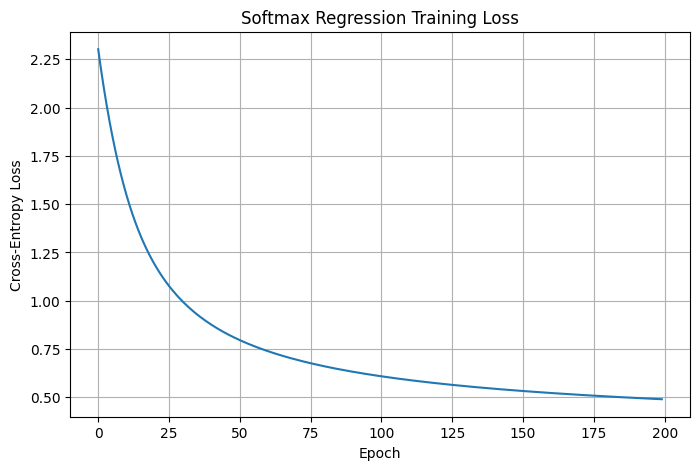

In [29]:
plt.figure(figsize=(8, 5))
plt.plot(model.loss_history)
plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("Softmax Regression Training Loss")
plt.grid()
plt.show()